# Оценка кредитоспособности заемщика с применением методов машинного обучения

# Основные библиотеки

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier 

from tensorflow import keras
from tensorflow.keras.layers import Dense, Flatten, Dropout

from sklearn.metrics import ( roc_auc_score, accuracy_score,
                              classification_report, roc_curve,
                              brier_score_loss, confusion_matrix )


from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# PCA
from sklearn.decomposition import PCA
# Metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.metrics import classification_report, RocCurveDisplay, roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV

# My preparing(class)
from assem.class_Preparing import Preparing
import pickle

# Загрузка датасета

(подробнее по ссылке:https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset/data?select=UCI_Credit_Card.csv):

In [135]:
df = pd.read_csv('UCI_Credit_Card.csv') 

In [65]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

| Наименование | Описание |
|---|---|
| **ID** | Идентификатор каждого клиента |
| **LIMIT_BAL** | Сумма выданного кредита в NT долларах |
| **SEX** | Пол (1 = мужской, 2 = женский) |
| **EDUCATION** | Образование (1 = аспирантура, 2 = университет, 3 = средняя школа, 4 = остальные и т.д.) |
| **MARRIAGE** | Семейное положение (1 = замужем, 2 = не замужем, 3 = остальные) |
| **AGE** | Возраст, лет |
| **PAY_0...PAY_6** | Статусы погашения за сентябрь–март 2005 года (-1 = платить должным образом, 1 = задержка платежа на один месяц, 2 = задержка платежа на два месяца, ... , 8 = задержка платежа на восемь месяцев, 9 = задержка платежа на девять месяцев и выше) |
| **BILL_AMT_1...BILL_AMT6** | Суммы выписок по счету за сентябрь–март 2005 года в NT долларах |
| **PAY_AMT1...PAY_AMT6** | Суммы предыдущих платежей за сентябрь–март 2005 года в NT долларах |
| **default.payment.next.month** | Платеж по умолчанию (1 = да, 0 = нет) |

In [66]:
df_pay = df.loc[:, ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'default.payment.next.month']]
df_pay.head(30)

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,default.payment.next.month
0,2,2,-1,-1,-2,-2,1
1,-1,2,0,0,0,2,1
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,-1,0,-1,0,0,0,0
5,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0
7,0,-1,-1,0,0,-1,0
8,0,0,2,0,0,0,0
9,-2,-2,-2,-2,-1,-1,0


In [67]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
anom = (df[pay_cols] <= 0).all(axis=1) & (df['default.payment.next.month'] == 1)
df_anom = df.loc[anom, pay_cols + ['default.payment.next.month']]

print(df_anom.head(10))
print(df_anom.shape[0])

     PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6  default.payment.next.month
21      -1     -1     -1     -1     -1     -1                           1
23      -2     -2     -2     -2     -2     -2                           1
45      -2     -2     -2     -2     -2     -2                           1
47       0      0     -1      0      0     -2                           1
60       0      0      0      0      0      0                           1
63       0      0      0     -2     -2     -2                           1
78       0      0      0      0      0      0                           1
82       0      0      0      0      0      0                           1
99       0      0      0      0      0     -1                           1
103      0      0      0      0      0      0                           1
2334


In [136]:
prep = Preparing(df)               
prep.warning()                  
prep.group_clients()

df_copy = prep.df_copy              # до удаления аномальных клиентов
df_new = prep.df_new                # после удаления аномальных клиентов
X_new, y_new = prep.X_pay_new, prep.y_new 
X_all_new = prep.X_all_new

print(X_new.shape, y_new.shape)

Рабочая версия
(27666, 6) (27666,)


AgeBin
(40, 50]    501
(25, 30]    479
(30, 35]    432
(35, 40]    413
(20, 25]    306
(50, 60]    179
(60, 80]     24
Name: count, dtype: int64


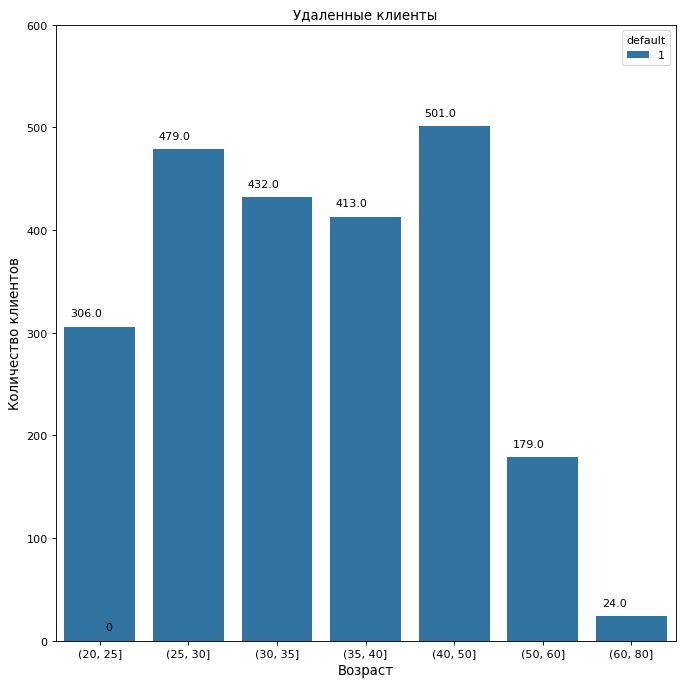

In [69]:
df_removed = prep.df_copy.loc[prep.index, :].copy() # анализ удаленных клиентов

df_removed['AgeBin'] = pd.cut(df_removed['AGE'], [20, 25, 30, 35, 40, 50, 60, 80])
print(df_removed['AgeBin'].value_counts())

df_removed['AgeBin'] = df_removed['AgeBin'].astype(str) # ось Х
AgeBin_order = ['(20, 25]', '(25, 30]', '(30, 35]', '(35, 40]', '(40, 50]', '(50, 60]', '(60, 80]']

fig, ax = plt.subplots(nrows=1, ncols=1, dpi=80, figsize=(10, 10))
sns.countplot(
    data=df_removed,
    x='AgeBin',
    hue='default',
    order=AgeBin_order,
    ax=ax
)

ax.set_xlabel('Возраст', fontsize=12)
ax.set_ylabel('Количество клиентов', fontsize=12)
ax.set_ylim(0, 600)
ax.set_title('Удаленные клиенты')

for p in ax.patches:
    ax.annotate((p.get_height()), (p.get_x()+0.065, p.get_height()+10))

plt.show()

LimitBin
(5000, 50000]        665
(200000, 300000]     394
(50000, 100000]      350
(150000, 200000]     309
(100000, 150000]     286
(300000, 400000]     204
(400000, 500000]     114
(500000, 1100000]     12
Name: count, dtype: int64


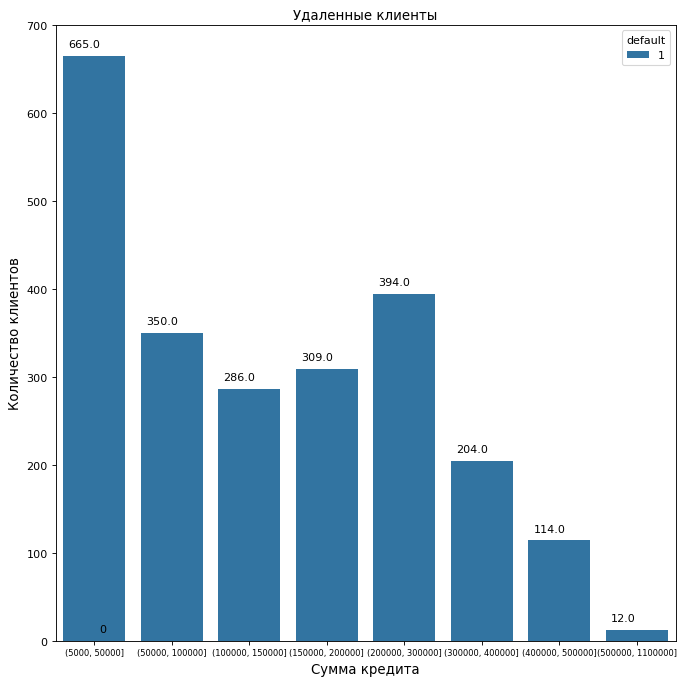

In [70]:
df_removed['LimitBin'] = pd.cut(df_removed['LIMIT_BAL'],[5000, 50000, 100000, 150000, 200000, 300000, 400000, 500000, 1100000])
print(df_removed['LimitBin'].value_counts())

df_removed['LimitBin'] = df_removed['LimitBin'].astype('str')

LimitBin_order = ['(5000, 50000]', '(50000, 100000]', '(100000, 150000]', '(150000, 200000]',
                '(200000, 300000]', '(300000, 400000]', '(400000, 500000]', '(500000, 1100000]']

fig, (ax) = plt.subplots(nrows = 1, 
                         ncols = 1,
                         dpi = 80,
                         figsize = (10, 10)
                        )

ax = sns.countplot(
    data=df_removed, 
    x='LimitBin', 
    hue="default", 
    order = LimitBin_order
)

ax.set_xlabel("Сумма кредита", fontsize= 12)
ax.set_ylabel("Количество клиентов", fontsize= 12)
ax.set_ylim(0,700)
ax.set_title('Удаленные клиенты')
ax.tick_params(axis="x", labelsize = 7.5)

for p in ax.patches:
    ax.annotate((p.get_height()), (p.get_x()+0.065, p.get_height()+10))

plt.show()

In [137]:
X = prep.X_all_new # 19 признаков
y = prep.y_new
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)

# Decision tree

In [72]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train, Y_train) 
dtree.score(X_train, Y_train), dtree.score(X_test, Y_test)

(0.9937346378138705, 0.8625126499927714)

In [9]:
param_space = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter':  ['best', 'random'],
    'max_depth': [10, 15, 20, 25, 30],
    'min_samples_split': [ 10, 15, 20, 25, 30],
    'min_samples_leaf': [5, 10, 15, 20, 25],
    'max_features': ['sqrt', 'log2']
}

grid_dtree = GridSearchCV(dtree, param_space) 
grid_dtree.fit(X_train, Y_train.ravel())       
print(grid_dtree.best_estimator_)  

DecisionTreeClassifier(criterion='log_loss', max_depth=10, max_features='log2',
                       min_samples_leaf=5, min_samples_split=30,
                       splitter='random')


In [73]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)
dtree = DecisionTreeClassifier(criterion='log_loss', 
                               max_depth=10, 
                               max_features='log2',
                               min_samples_leaf=5, 
                               min_samples_split=30,
                               splitter='random',
                               random_state=42
                              )
dtree.fit(X_train, Y_train) 
dtree.score(X_train, Y_train), dtree.score(X_test, Y_test)

(0.8682346137163237, 0.8729217869018361)

In [74]:
y_pred_train = dtree.predict(X_train)
y_pred_test = dtree.predict(X_test)

print(classification_report(Y_train, y_pred_train))
print(classification_report(Y_test,  y_pred_test)) 

              precision    recall  f1-score   support

           0       0.89      0.97      0.93     17529
           1       0.65      0.33      0.44      3220

    accuracy                           0.87     20749
   macro avg       0.77      0.65      0.68     20749
weighted avg       0.85      0.87      0.85     20749

              precision    recall  f1-score   support

           0       0.89      0.97      0.93      5835
           1       0.68      0.35      0.46      1082

    accuracy                           0.87      6917
   macro avg       0.79      0.66      0.70      6917
weighted avg       0.86      0.87      0.86      6917



In [75]:
with open('dtr.pkl', 'wb') as file:
    pickle.dump( dtree, file, protocol=pickle.HIGHEST_PROTOCOL)

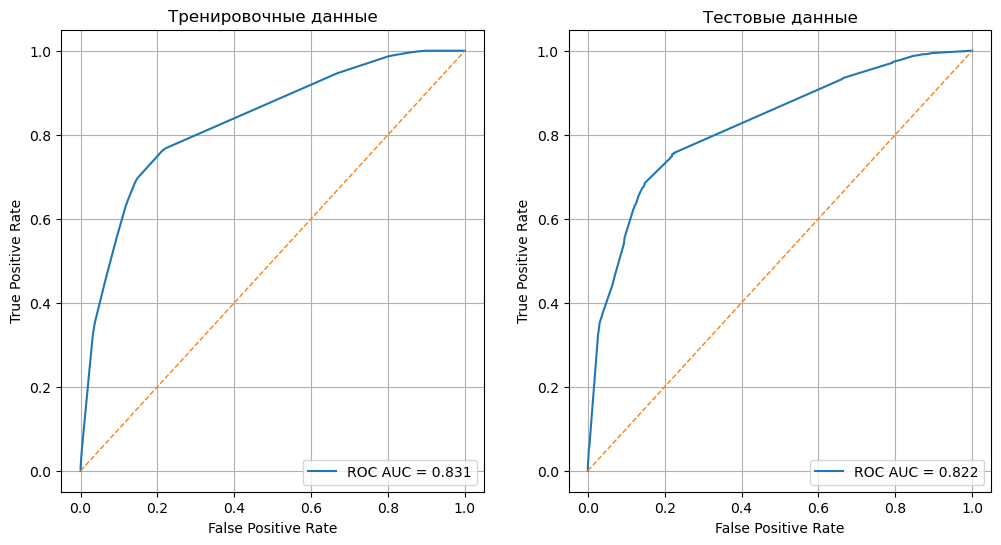

In [76]:
y_score = dtree.predict_proba(X_train)[:, 1]   
fpr, tpr, thr = roc_curve(Y_train, y_score)
auc = roc_auc_score(Y_train, y_score)

fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

ax1.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax1.plot([0, 1], [0, 1], '--', linewidth=1) 
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Тренировочные данные')
ax1.legend(loc='lower right')
ax1.grid(True)

y_score = dtree.predict_proba(X_test)[:, 1]   
fpr, tpr, thr = roc_curve(Y_test, y_score)
auc = roc_auc_score(Y_test, y_score)

ax2.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax2.plot([0, 1], [0, 1], '--', linewidth=1) 
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Тестовые данные')
ax2.legend(loc='lower right')
ax2.grid(True)

fig.savefig('ROC_AUC_DT_train_test_dtr_big.png', bbox_inches='tight')

[[16955   574]
 [ 2160  1060]]
[[5658  177]
 [ 702  380]]


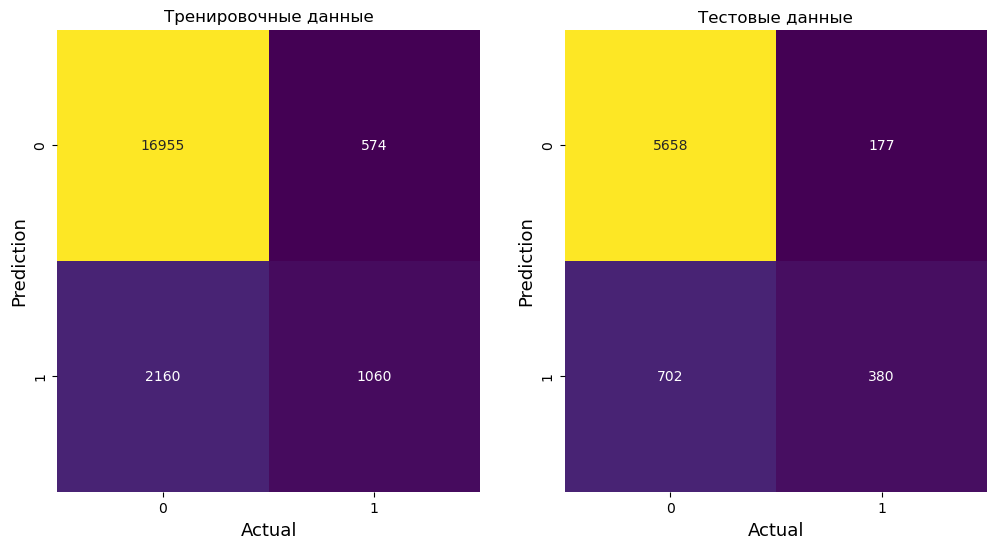

In [77]:
fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

y_pred_train = dtree.predict(X_train)                                              
cm = confusion_matrix(Y_train, y_pred_train, labels=[0, 1]) 
print(str(cm))                                                            

sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax1)
ax1.set_ylabel('Prediction',fontsize = 13)                                           
ax1.set_xlabel('Actual',fontsize = 13) 
ax1.set_title('Тренировочные данные')

y_pred_test = dtree.predict(X_test)                                              
cm = confusion_matrix(Y_test, y_pred_test, labels=[0, 1]) 
print(str(cm))                                                            

sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax2)
ax2.set_ylabel('Prediction',fontsize = 13)                                           
ax2.set_xlabel('Actual',fontsize = 13)
ax2.set_title('Тестовые данные')

fig.savefig('matrix_dtr_train_test_big.png', bbox_inches='tight')

# Случайный лес

In [78]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)
rfc = RandomForestClassifier(random_state=42)
rfc.fit( X_train, Y_train )
rfc.score( X_train, Y_train ), rfc.score( X_test, Y_test )

(0.9937346378138705, 0.8837646378487783)

In [30]:
param_space = {
    'n_estimators': [60, 80, 120],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [15, 30, 50],
    'min_samples_split': [ 10, 30, 60],
    'min_samples_leaf': [10, 30, 60],
    'max_features': ['sqrt', 'log2']
}

grid_rfc = GridSearchCV( rfc, param_space, n_jobs=-1 )  
grid_rfc.fit( X_train, Y_train.ravel() )      
print( grid_rfc.best_estimator_ )  

RandomForestClassifier(max_depth=15, min_samples_leaf=60, min_samples_split=10,
                       n_estimators=60, random_state=42)


In [79]:
X_train, X_test, Y_train, Y_test = train_test_split( X, y, test_size=0.25, random_state=0 )
rfc = RandomForestClassifier( max_depth=15, 
                             min_samples_leaf=60, 
                             min_samples_split=10,
                             n_estimators=60, 
                             random_state=42)
rfc.fit( X_train, Y_train )
rfc.score( X_train, Y_train ), rfc.score( X_test, Y_test )

(0.893874403585715, 0.8905594911088622)

In [80]:
y_pred_train = rfc.predict(X_train)
y_pred_test = rfc.predict(X_test)

print(classification_report(Y_train, y_pred_train))
print(classification_report(Y_test,  y_pred_test)) 

              precision    recall  f1-score   support

           0       0.92      0.95      0.94     17529
           1       0.69      0.57      0.62      3220

    accuracy                           0.89     20749
   macro avg       0.81      0.76      0.78     20749
weighted avg       0.89      0.89      0.89     20749

              precision    recall  f1-score   support

           0       0.92      0.96      0.94      5835
           1       0.70      0.53      0.60      1082

    accuracy                           0.89      6917
   macro avg       0.81      0.74      0.77      6917
weighted avg       0.88      0.89      0.88      6917



In [81]:
with open('rfc.pkl', 'wb') as file:
    pickle.dump( rfc, file, protocol=pickle.HIGHEST_PROTOCOL)

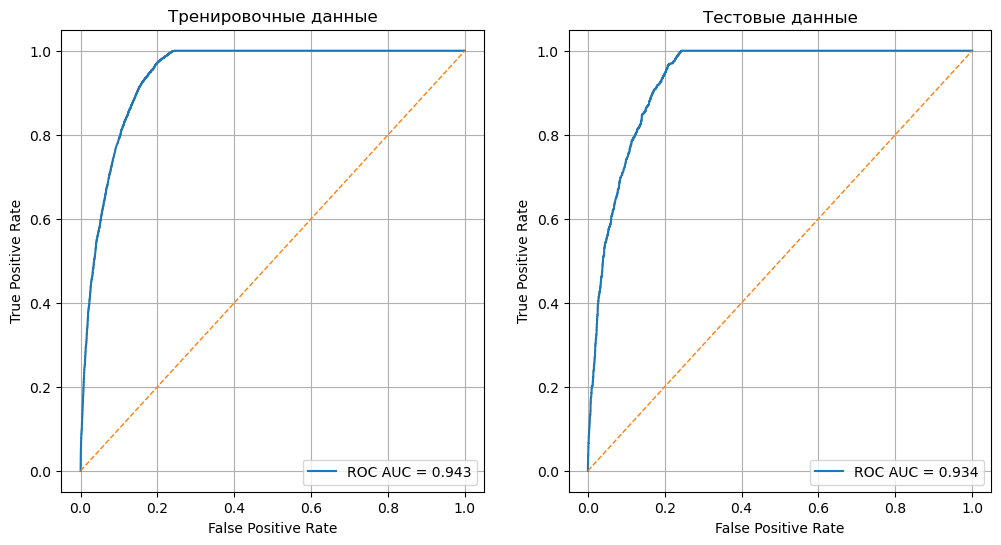

In [82]:
y_score = rfc.predict_proba(X_train)[:, 1]   
fpr, tpr, thr = roc_curve(Y_train, y_score)
auc = roc_auc_score(Y_train, y_score)

fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

ax1.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax1.plot([0, 1], [0, 1], '--', linewidth=1) 
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Тренировочные данные')
ax1.legend(loc='lower right')
ax1.grid(True)

y_score = rfc.predict_proba(X_test)[:, 1]   
fpr, tpr, thr = roc_curve(Y_test, y_score)
auc = roc_auc_score(Y_test, y_score)

ax2.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax2.plot([0, 1], [0, 1], '--', linewidth=1) 
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Тестовые данные')
ax2.legend(loc='lower right')
ax2.grid(True)

fig.savefig('ROC_AUC_DT_train_test_rfc_big.png', bbox_inches='tight')

[[16717   812]
 [ 1390  1830]]
[[5586  249]
 [ 508  574]]


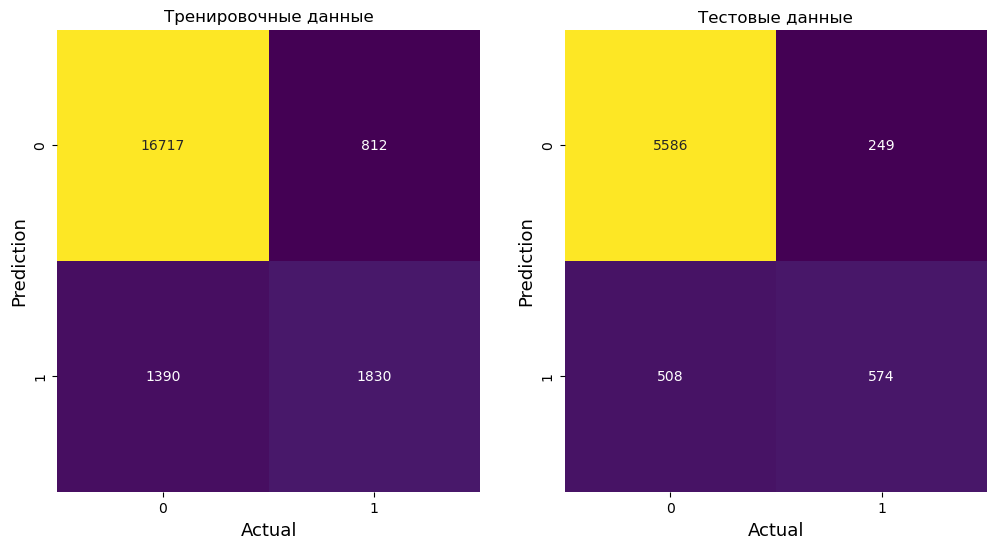

In [83]:
fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

y_pred_train = rfc.predict(X_train)                                              
cm = confusion_matrix(Y_train, y_pred_train, labels=[0, 1]) 
print(str(cm))                                                            

sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax1)
ax1.set_ylabel('Prediction',fontsize = 13)                                           
ax1.set_xlabel('Actual',fontsize = 13) 
ax1.set_title('Тренировочные данные')

y_pred_test = rfc.predict(X_test)                                              
cm = confusion_matrix(Y_test, y_pred_test, labels=[0, 1]) 
print(str(cm))                                                            

sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax2)
ax2.set_ylabel('Prediction',fontsize = 13)                                           
ax2.set_xlabel('Actual',fontsize = 13)
ax2.set_title('Тестовые данные')

fig.savefig('matrix_dtr_train_test_big.png', bbox_inches='tight')

# Градиентный бустинг

In [102]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)
boost_gr = GradientBoostingClassifier(random_state=42)
boost_gr.fit(X_train, Y_train)
boost_gr.score(X_train, Y_train), boost_gr.score(X_test, Y_test)

(0.898404742397224, 0.8882463495735146)

In [103]:
y_pred_train = boost_gr.predict(X_train)
y_pred_test = boost_gr.predict(X_test)

print(classification_report(Y_train, y_pred_train))
print(classification_report(Y_test,  y_pred_test)) 

              precision    recall  f1-score   support

           0       0.93      0.95      0.94     17529
           1       0.69      0.63      0.66      3220

    accuracy                           0.90     20749
   macro avg       0.81      0.79      0.80     20749
weighted avg       0.89      0.90      0.90     20749

              precision    recall  f1-score   support

           0       0.92      0.95      0.93      5835
           1       0.67      0.57      0.61      1082

    accuracy                           0.89      6917
   macro avg       0.80      0.76      0.77      6917
weighted avg       0.88      0.89      0.88      6917



In [90]:
with open('boost_gr.pkl', 'wb') as file:
    pickle.dump( boost_gr, file, protocol=pickle.HIGHEST_PROTOCOL)

In [42]:
param_space = {
    'loss': ['log_loss', 'exponential'],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [30, 50, 100],
    'subsample': [0.8, 1.0],
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': [5, 10, 15],
    'min_samples_split': [ 5, 10, 20],
    'min_samples_leaf': [5, 15, 20]
}

grid_boost_gr  = GridSearchCV( boost_gr , param_space, n_jobs=-1 )  
grid_boost_gr.fit(X_train, Y_train.ravel())      
print(grid_boost_gr.best_estimator_)  

GradientBoostingClassifier(max_depth=5, min_samples_leaf=5,
                           min_samples_split=20, n_estimators=30,
                           random_state=42)


In [91]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)
boost_gr = GradientBoostingClassifier(max_depth=5, 
                                      min_samples_leaf=5,
                                      min_samples_split=20,
                                      n_estimators=30,
                                      random_state=42)
boost_gr.fit(X_train, Y_train)
boost_gr.score(X_train, Y_train), boost_gr.score(X_test, Y_test)

(0.9027904959275146, 0.889836634379066)

In [92]:
y_pred_train = boost_gr.predict(X_train)
y_pred_test = boost_gr.predict(X_test)

print(classification_report(Y_train, y_pred_train))
print(classification_report(Y_test,  y_pred_test)) 

              precision    recall  f1-score   support

           0       0.93      0.96      0.94     17529
           1       0.72      0.61      0.66      3220

    accuracy                           0.90     20749
   macro avg       0.83      0.78      0.80     20749
weighted avg       0.90      0.90      0.90     20749

              precision    recall  f1-score   support

           0       0.92      0.95      0.94      5835
           1       0.69      0.54      0.61      1082

    accuracy                           0.89      6917
   macro avg       0.80      0.75      0.77      6917
weighted avg       0.88      0.89      0.88      6917



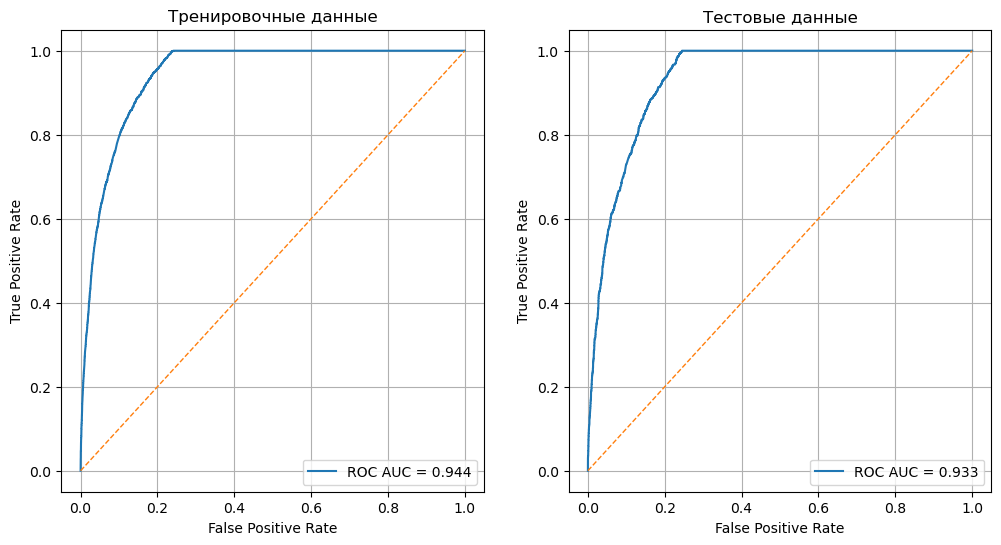

In [104]:
y_score = boost_gr.predict_proba(X_train)[:, 1]   
fpr, tpr, thr = roc_curve(Y_train, y_score)
auc = roc_auc_score(Y_train, y_score)

fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

ax1.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax1.plot([0, 1], [0, 1], '--', linewidth=1) 
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Тренировочные данные')
ax1.legend(loc='lower right')
ax1.grid(True)

y_score = boost_gr.predict_proba(X_test)[:, 1]   
fpr, tpr, thr = roc_curve(Y_test, y_score)
auc = roc_auc_score(Y_test, y_score)

ax2.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax2.plot([0, 1], [0, 1], '--', linewidth=1) 
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Тестовые данные')
ax2.legend(loc='lower right')
ax2.grid(True)

fig.savefig('ROC_AUC_DT_train_test_rfc_big.png', bbox_inches='tight')

# Нейронная сеть

![График](nn.png)
*Рисунок 1 – Архитектура нейронной сети*

In [120]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)

epochs = 20

model = keras.Sequential()            
model.add(keras.Input(shape=(19,)))  
model.add(Dense(32, activation='relu'))   
model.add(Dropout(0.25))
model.add(Dense(32, activation='relu'))    
model.add(Dropout(0.25))

model.add(keras.layers.Dense(1, activation='sigmoid')) 

opt = keras.optimizers.Adam(learning_rate=0.01)
metrics = keras.metrics.BinaryAccuracy(name="accuracy", dtype=None, threshold=0.5)

model.compile(optimizer=opt, loss='mse', metrics=metrics)
fit_history = model.fit(X_train, Y_train, 
                        batch_size=128,
                        validation_data=(X_test, Y_test),
                        epochs=epochs)

Epoch 1/20
163/163 [==============================] - 1s 2ms/step - loss: 0.2576 - accuracy: 0.7424 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 2/20
163/163 [==============================] - 0s 945us/step - loss: 0.1555 - accuracy: 0.8445 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 3/20
163/163 [==============================] - 0s 956us/step - loss: 0.1591 - accuracy: 0.8409 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 4/20
163/163 [==============================] - 0s 966us/step - loss: 0.1569 - accuracy: 0.8431 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 5/20
163/163 [==============================] - 0s 984us/step - loss: 0.1594 - accuracy: 0.8406 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 6/20
163/163 [==============================] - 0s 951us/step - loss: 0.1566 - accuracy: 0.8434 - val_loss: 0.1564 - val_accuracy: 0.8436
Epoch 7/20
163/163 [==============================] - 0s 967us/step - loss: 0.1526 - accuracy: 0.8474 - val_loss: 0.1564 - val_accuracy: 0

In [138]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scaler = MinMaxScaler()
#scaler = StandardScaler()
data_standardized = scaler.fit_transform(df_new.loc[:,columns_st])
#pd.concat([ pd.DataFrame(data_standardized.T, columns_st), df_new.loc[:,columns_d]], axis=1)
df1, df2 = data_standardized, np.array( df_new.loc[:,columns_d] )

columns_old = ['LIMIT_BAL','PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6','BILL_AMT1',
                'BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6',
                 'PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']
df1 = pd.DataFrame( df1, columns = columns_st)
df1_ = df1.drop(['LIMIT_BAL'], axis=1)
df_st = np.concatenate( (np.array([df1.LIMIT_BAL]).T, df2, np.array(df1_)) , axis=1) 
df_st
#scaler.inverse_transform([df_st[0,:]])
example = df_new.loc[0,columns_old]
example = pd.DataFrame( [np.array(example)], columns = columns_old )
scaler.transform( example.loc[:, columns_st] ), data_standardized[0,:]

(array([[0.01010101, 0.14998173, 0.06916432, 0.08672289, 0.16013776,
         0.08064809, 0.17856694, 0.        , 0.00040908, 0.        ,
         0.        , 0.        , 0.        ]]),
 array([0.01010101, 0.14998173, 0.06916432, 0.08672289, 0.16013776,
        0.08064809, 0.17856694, 0.        , 0.00040908, 0.        ,
        0.        , 0.        , 0.        ]))

In [139]:
with open('scaler.pkl', 'wb') as file:
    pickle.dump( scaler, file, protocol=pickle.HIGHEST_PROTOCOL)

In [140]:
with open("./scaler.pkl", "rb") as f: # rb - режим чтения, ./model.pkl - файл куда сохраняется модель
    scaler = pickle.load(f)
exp_st = scaler.transform( example.loc[:, columns_st] )

In [141]:
X = data_standardized # 19 признаков вместе с дисциплинарными признаками
X = df_st # 19 признаков вместе с дисциплинарными признаками
y = y_new

X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.25, random_state=0)

epochs = 20

model = keras.Sequential()            
model.add(keras.Input(shape=(19,)))  
model.add(Dense(256, activation='relu'))   
model.add(Dropout(0.25))
model.add(Dense(256, activation='relu'))    
model.add(Dropout(0.25))

model.add(keras.layers.Dense(1, activation='sigmoid'))
#model.add(keras.layers.Dense(2, activation = keras.ops.tanh))  

opt = keras.optimizers.Adam(learning_rate=0.01)
metrics = keras.metrics.BinaryAccuracy(name="accuracy", dtype=None, threshold=0.5)

model.compile(optimizer=opt, loss='mse', metrics=metrics)
fit_history = model.fit(X_train, Y_train, 
                        batch_size=128,
                        validation_data=(X_test, Y_test),
                        epochs=epochs)

model.save("my_model.keras")

Epoch 1/20
163/163 [==============================] - 1s 3ms/step - loss: 0.1001 - accuracy: 0.8632 - val_loss: 0.0795 - val_accuracy: 0.8861
Epoch 2/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0789 - accuracy: 0.8862 - val_loss: 0.0805 - val_accuracy: 0.8846
Epoch 3/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0787 - accuracy: 0.8842 - val_loss: 0.0792 - val_accuracy: 0.8880
Epoch 4/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0778 - accuracy: 0.8862 - val_loss: 0.0803 - val_accuracy: 0.8882
Epoch 5/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0769 - accuracy: 0.8909 - val_loss: 0.0780 - val_accuracy: 0.8875
Epoch 6/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0777 - accuracy: 0.8867 - val_loss: 0.0776 - val_accuracy: 0.8890
Epoch 7/20
163/163 [==============================] - 0s 2ms/step - loss: 0.0761 - accuracy: 0.8905 - val_loss: 0.0788 - val_accuracy: 0.8875
Epoch 

In [142]:
model = keras.models.load_model("my_model.keras")

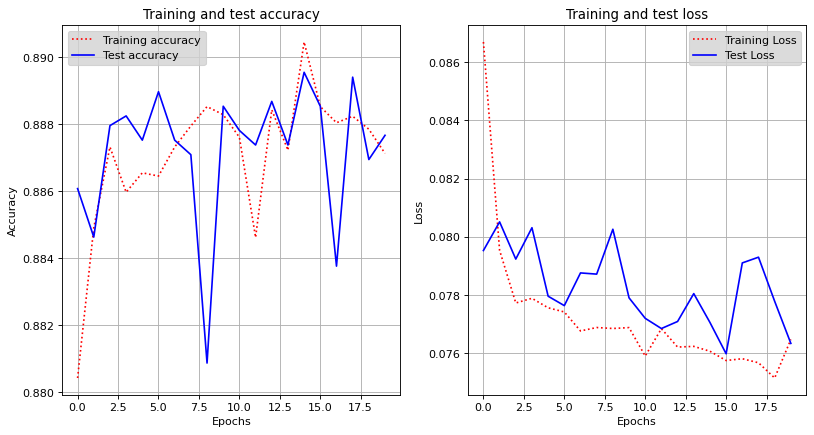

In [143]:
#  accuracy and loss-function
acc = fit_history.history['accuracy']
val_acc = fit_history.history['val_accuracy']
loss = fit_history.history['loss']
val_loss = fit_history.history['val_loss']
epochs = range(len(acc))

fig, ( ax1, ax2 ) = plt.subplots( nrows=1, 
                                  ncols=2,
                                  dpi= 80,
                                  figsize=(12,6))
ax1.plot(epochs, acc, 'r:', label='Training accuracy')
ax1.plot(epochs, val_acc, 'b', label='Test accuracy')
ax1.set_title('Training and test accuracy')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.grid(True)
ax1.legend(facecolor="lightgrey")

ax2.plot(epochs, loss, 'r:', label='Training Loss')
ax2.plot(epochs, val_loss, 'b', label='Test Loss')
ax2.set_title('Training and test loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.grid(True)
ax2.legend(facecolor="lightgrey")

In [144]:
proba_train = model.predict(X_train)
proba_test = model.predict(X_test)

In [145]:
col1_train = proba_train.T[0]
y_proba_train = np.array([1-col1_train,col1_train]).T
y_proba_test = np.array([1-col1_test,col1_test]).T

y_pred_train = np.zeros(len(col1_train)).astype(int) 
y_pred_train[col1_train>0.5] = 1

col1_test = proba_test.T[0]
y_proba_test = np.array([1-col1_test,col1_test]).T

y_pred_test = np.zeros(len(col1_test)).astype(int) 
y_pred_test[col1_test>0.5] = 1

[[16697   832]
 [ 1400  1820]]
[[5575  260]
 [ 517  565]]


Text(0.5, 1.0, 'Тестовые данные')

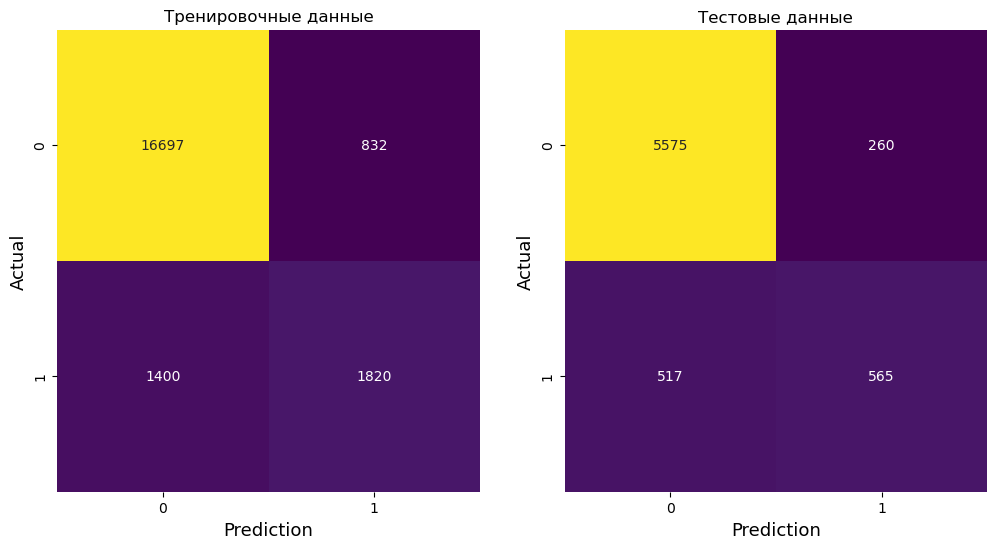

In [146]:
fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

#y_pred_train = dtree.predict(X_train)                                              
cm = confusion_matrix(Y_train, y_pred_train, labels=[0, 1]) 
print( str(cm) )                                                            
sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax1)
ax1.set_ylabel('Actual',fontsize = 13)                                           
ax1.set_xlabel('Prediction',fontsize = 13) 
ax1.set_title('Тренировочные данные')

#y_pred_test = dtree.predict(X_test)                                              
cm = confusion_matrix(Y_test, y_pred_test, labels=[0, 1]) 
print( str(cm) )                                                            

sns.heatmap(cm, annot=True, fmt='d',  cmap='viridis', cbar=False, ax = ax2)
ax2.set_ylabel('Actual',fontsize = 13)                                           
ax2.set_xlabel('Prediction',fontsize = 13)
ax2.set_title('Тестовые данные')

#fig.savefig('matrix_nn_train_test_big.png', bbox_inches='tight')

In [147]:
print(classification_report(Y_train, y_pred_train))
print(classification_report(Y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.92      0.95      0.94     17529
           1       0.69      0.57      0.62      3220

    accuracy                           0.89     20749
   macro avg       0.80      0.76      0.78     20749
weighted avg       0.89      0.89      0.89     20749

              precision    recall  f1-score   support

           0       0.92      0.96      0.93      5835
           1       0.68      0.52      0.59      1082

    accuracy                           0.89      6917
   macro avg       0.80      0.74      0.76      6917
weighted avg       0.88      0.89      0.88      6917



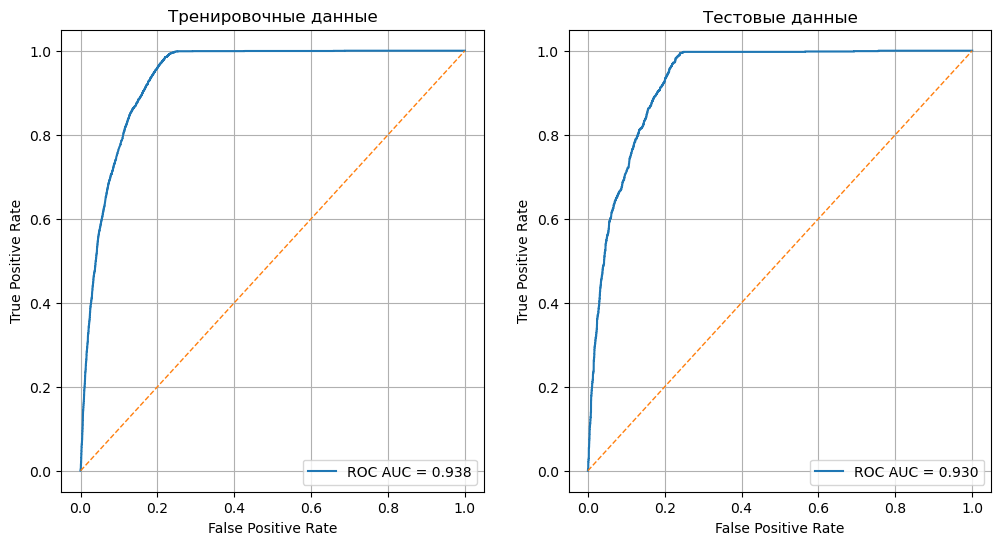

In [148]:
y_score = proba_train[:,0]
fpr, tpr, thr = roc_curve(Y_train, y_score)
auc = roc_auc_score(Y_train, y_score)

fig, (ax1, ax2) = plt.subplots( nrows = 1, 
                                ncols = 2,
                                figsize=(12,6) )

ax1.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax1.plot([0, 1], [0, 1], '--', linewidth=1) 
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Тренировочные данные')
ax1.legend(loc='lower right')
ax1.grid(True)

# y_score = dtree.predict_proba(X_test)[:, 1]  
y_score =  proba_test[:,0]
fpr, tpr, thr = roc_curve(Y_test, y_score)
auc = roc_auc_score(Y_test, y_score)

ax2.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
ax2.plot([0, 1], [0, 1], '--', linewidth=1) 
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Тестовые данные')
ax2.legend(loc='lower right')
ax2.grid(True)

streamlit run app.py --server.runOnSave True